In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
import os
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score
from sentence_transformers import SentenceTransformer

/home/christ/Downloads/Telegram Desktop/M1/M1 Avignon universite/approches neuronales/TP/env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load sentence embedding model (384 dim)
embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 857.56it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [3]:
folder = os.listdir('data')
train_file = folder[1]  # train_hotel.csv
test_file = folder[0]   # test_hotel.csv
val_file = folder[2]    # valid_hotel.csv

def load_data(file_path):
    data = pd.read_csv(os.path.join('data', file_path))
    return data

data_train = load_data(train_file)
data_test = load_data(test_file)
data_val = load_data(val_file)

print(data_train['Review'].head())
print('Rating unique:', data_train['Rating'].unique())  # Confirm 1-5

0    nice hotel expensive parking got good deal sta...
1    ok nothing special charge diamond member hilto...
2    nice rooms not 4* experience hotel monaco seat...
3    unique, great stay, wonderful time hotel monac...
4    great stay great stay, went seahawk game aweso...
Name: Review, dtype: object
Rating unique: [4 2 3 5 1]


In [4]:
def vectorize_data(data, col_name):
    return embedding_model.encode(data[col_name].tolist())

# Vectorize embeddings
data_train_vec = vectorize_data(data_train, 'Review')
data_train_labels = torch.tensor(data_train['Rating'].values - 1, dtype=torch.long)  # 0-4 classes

print('Train shape:', data_train_vec.shape)
print('Classes:', data_train_labels.unique())

Train shape: (18491, 384)
Classes: tensor([0, 1, 2, 3, 4])


In [5]:
data_val_vec = vectorize_data(data_val, 'Review')
data_val_labels = torch.tensor(data_val['Rating'].values - 1, dtype=torch.long)

In [6]:
class ClassificationModel(nn.Module):
    def __init__(self, input_dim=384, num_classes=5):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.9),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.8),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.model(x)

row, dim = data_train_vec.shape
print(f'Input dim: {dim}, Classes: 5')

device = 'cuda' if torch.cuda.is_available() else 'cpu'

Input dim: 384, Classes: 5


In [ ]:
batch_size = 256
n_samples = data_train_vec.shape[0]
epochs = 40

n_samples_val = data_val_vec.shape[0]
batch_val_size = 256

model = ClassificationModel(dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.00002)

all_train_loss = []
all_val_loss = []
all_val_acc = []

In [35]:
model.train()
for epoch in range(epochs):
    total_loss = 0
    for start in range(0, n_samples, batch_size):
        end = start + batch_size
        
        X_batch = torch.tensor(data_train_vec[start:end], dtype=torch.float32).to(device)
        Y_batch = data_train_labels[start:end].to(device)

        logits = model(X_batch)
        loss = loss_function(logits, Y_batch)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_train_loss = total_loss / (n_samples / batch_size)
    all_train_loss.append(avg_train_loss)

    # Validation
    model.eval()
    total_val_loss = 0
    val_preds = []
    val_trues = []
    with torch.no_grad():
        for start in range(0, n_samples_val, batch_val_size):
            end = start + batch_val_size
            X_val_batch = torch.tensor(data_val_vec[start:end], dtype=torch.float32).to(device)
            Y_val_batch = data_val_labels[start:end].to(device)

            logits = model(X_val_batch)
            loss = loss_function(logits, Y_val_batch)
            total_val_loss += loss.item()
            
            preds = logits.argmax(dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_trues.extend(Y_val_batch.cpu().numpy())
    
    avg_val_loss = total_val_loss / (n_samples_val / batch_val_size)
    val_acc = accuracy_score(val_trues, val_preds)
    all_val_loss.append(avg_val_loss)
    all_val_acc.append(val_acc)
    
    print(f'Epoch {epoch+1}/{epochs}, Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}')

print(f'Avg train loss: {np.mean(all_train_loss):.4f}')

Epoch 1/40, Train Loss: 1.8525, Val Loss: 1.6560, Val Acc: 0.0550
Epoch 2/40, Train Loss: 1.6300, Val Loss: 1.6533, Val Acc: 0.0570
Epoch 3/40, Train Loss: 1.6268, Val Loss: 1.6498, Val Acc: 0.0620
Epoch 4/40, Train Loss: 1.6227, Val Loss: 1.6450, Val Acc: 0.1100
Epoch 5/40, Train Loss: 1.6165, Val Loss: 1.6376, Val Acc: 0.2780
Epoch 6/40, Train Loss: 1.6067, Val Loss: 1.6256, Val Acc: 0.4710
Epoch 7/40, Train Loss: 1.5914, Val Loss: 1.6072, Val Acc: 0.5110
Epoch 8/40, Train Loss: 1.5679, Val Loss: 1.5789, Val Acc: 0.5160
Epoch 9/40, Train Loss: 1.5326, Val Loss: 1.5376, Val Acc: 0.5210
Epoch 10/40, Train Loss: 1.4832, Val Loss: 1.4836, Val Acc: 0.5310
Epoch 11/40, Train Loss: 1.4221, Val Loss: 1.4224, Val Acc: 0.5310
Epoch 12/40, Train Loss: 1.3565, Val Loss: 1.3607, Val Acc: 0.5440
Epoch 13/40, Train Loss: 1.2938, Val Loss: 1.3053, Val Acc: 0.5570
Epoch 14/40, Train Loss: 1.2409, Val Loss: 1.2608, Val Acc: 0.5570
Epoch 15/40, Train Loss: 1.1996, Val Loss: 1.2269, Val Acc: 0.5560
Epoc

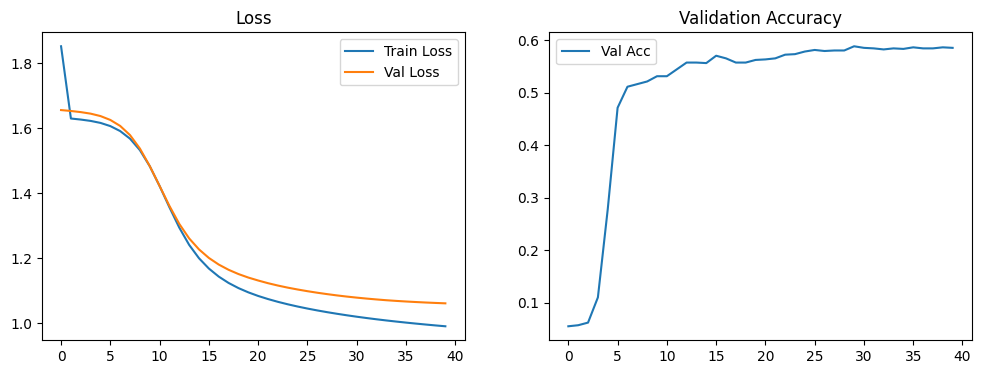

In [36]:
x = np.arange(epochs)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(x[:len(all_train_loss)], all_train_loss, label='Train Loss')
plt.plot(x[:len(all_val_loss)], all_val_loss, label='Val Loss')
plt.legend()
plt.title('Loss')

plt.subplot(1, 2, 2)
plt.plot(x[:len(all_val_acc)], all_val_acc, label='Val Acc')
plt.legend()
plt.title('Validation Accuracy')
plt.show()

In [37]:
data_test_vec = vectorize_data(data_test, 'Review')
data_test_labels = torch.tensor(data_test['Rating'].values - 1, dtype=torch.long)
print('Test shape:', data_test_vec.shape)

Test shape: (1000, 384)


In [38]:
model.eval()
batch_test_size = 256
n_samples_test = data_test_vec.shape[0]

all_test_preds = []
all_test_trues = []
total_test_loss = 0

with torch.no_grad():
    for start in range(0, n_samples_test, batch_test_size):
        end = start + batch_test_size
        X_test_batch = torch.tensor(data_test_vec[start:end], dtype=torch.float32).to(device)
        Y_test_batch = data_test_labels[start:end].to(device)

        logits = model(X_test_batch)
        loss = loss_function(logits, Y_test_batch)
        total_test_loss += loss.item()
        
        preds = logits.argmax(dim=1)
        all_test_preds.extend(preds.cpu().numpy())
        all_test_trues.extend(Y_test_batch.cpu().numpy())

avg_test_loss = total_test_loss / (n_samples_test / batch_test_size)
test_acc = accuracy_score(all_test_trues, all_test_preds)
print(f'Test Loss: {avg_test_loss:.4f}, Test Accuracy: {test_acc:.4f}')

# Detailed metrics
print('\nClassification Report:')
print(classification_report(all_test_trues, all_test_preds, target_names=['1', '2', '3', '4', '5']))

cm = confusion_matrix(all_test_trues, all_test_preds)
print('\nConfusion Matrix:')
print(cm)

# Memory
if torch.cuda.is_available():
    print(f'GPU Mem allocated: {torch.cuda.memory_allocated() / 1024**2:.2f} MB')

Test Loss: 0.9939, Test Accuracy: 0.5910

Classification Report:
              precision    recall  f1-score   support

           1       0.62      0.63      0.63        57
           2       0.42      0.62      0.50        81
           3       0.38      0.43      0.41       109
           4       0.49      0.37      0.42       287
           5       0.73      0.76      0.74       466

    accuracy                           0.59      1000
   macro avg       0.53      0.56      0.54      1000
weighted avg       0.59      0.59      0.59      1000


Confusion Matrix:
[[ 36  17   4   0   0]
 [ 17  50   9   5   0]
 [  3  25  47  26   8]
 [  1  14  43 105 124]
 [  1  13  20  79 353]]
GPU Mem allocated: 112.22 MB
